In [ ]:
!pip install biopython
from Bio import Entrez
import time
import re

# =========================================================
# CONFIGURATION
# =========================================================
# REQUIRED: NCBI needs an email to use their public API
Entrez.email = "arin.heatup@gmail.com"

OUTPUT_NEWICK = "Tree_of_Life_Phyla.nwk"

DOMAIN_TAX_IDS = {
    "Bacteria": "2",
    "Eukarya": "2759",    # NCBI TaxID for Eukaryota
    "Archaea": "2157",
    "Viruses": "10239"
}

def clean_newick_name(name):
    """
    Newick format strictly forbids certain characters like commas,
    colons, and parentheses in node names. This cleans them.
    """
    # Replace spaces with underscores (standard Newick practice)
    name = name.replace(" ", "_")
    # Remove any illegal Newick structural characters
    name = re.sub(r'[(),:;]', '', name)
    return name

def fetch_all_phyla(domain_name, tax_id):
    """Queries NCBI Taxonomy to get all recognized phyla for a domain."""
    query = f"txid{tax_id}[Subtree] AND phylum[Rank]"
    print(f"Fetching NCBI baseline for {domain_name}...")

    try:
        search_handle = Entrez.esearch(db="taxonomy", term=query, retmax=2000)
        search_results = Entrez.read(search_handle)
        search_handle.close()

        tax_ids = search_results["IdList"]
        if not tax_ids:
            return []

        fetch_handle = Entrez.efetch(db="taxonomy", id=",".join(tax_ids), retmode="xml")
        tax_records = Entrez.read(fetch_handle)
        fetch_handle.close()

        # Clean the names for Newick compatibility
        phyla_list = [clean_newick_name(record["ScientificName"]) for record in tax_records]

        time.sleep(0.5) # Politeness delay
        return list(set(phyla_list))

    except Exception as e:
        print(f"Error fetching data for {domain_name}: {e}")
        return []

# =========================================================
# BUILD THE NEWICK STRING
# =========================================================
print("--- Step 1: Fetching Taxonomic Data ---")
domain_strings = []

for domain, tax_id in DOMAIN_TAX_IDS.items():
    phyla = fetch_all_phyla(domain, tax_id)
    print(f" -> Found {len(phyla)} phyla for {domain}")

    if phyla:
        # Format: (Phylum1,Phylum2,Phylum3)Domain
        phyla_str = ",".join(phyla)
        domain_strings.append(f"({phyla_str}){domain}")

# Combine all domains into the Root
# Format: (Domain1,Domain2,Domain3)Root;
final_newick = f"({','.join(domain_strings)})Tree_Of_Life;"

# =========================================================
# SAVE TO FILE
# =========================================================
print("\n--- Step 2: Saving Newick File ---")
with open(OUTPUT_NEWICK, "w") as f:
    f.write(final_newick)

print(f"✅ SUCCESS! Generated {OUTPUT_NEWICK}")
print("You can now upload this directly to iTOL as your base tree.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 34.2 MB/s eta 0:00:00
--- Step 1: Fetching Taxonomic Data ---
Fetching NCBI baseline for Bacteria...
 -> Found 192 phyla for Bacteria
Fetching NCBI baseline for Eukarya...
 -> Found 79 phyla for Eukarya
Fetching NCBI baseline for Archaea...
 -> Found 45 phyla for Archaea
Fetching NCBI baseline for Viruses...
 -> Found 22 phyla for Viruses

--- Step 2: Saving Newick File ---
✅ SUCCESS! Generated Tree_of_Life_Phyla.nwk
You can now upload this directly to iTOL as your base tree.


In [ ]:
from Bio import Entrez
import time
import re

# =========================================================
# CONFIGURATION
# =========================================================
Entrez.email = "arin.heatup@gmail.com"
OUTPUT_NEWICK = "Tree_of_Life_Phyla.nwk"
OUTPUT_GLOBAL_BG = "itol_domain_backgrounds.txt"

DOMAIN_TAX_IDS = {
    "Bacteria": "2",
    "Eukarya": "2759",
    "Archaea": "2157",
    "Viruses": "10239"
}

# Extremely light pastel shades for the continuous background
DOMAIN_LIGHT_COLORS = {
    "Bacteria": "rgba(99,110,250,0.08)",
    "Eukarya": "rgba(239,85,59,0.08)",
    "Archaea": "rgba(0,204,150,0.08)",
    "Viruses": "rgba(171,99,250,0.08)"
}

def clean_newick_name(name):
    name = name.replace(" ", "_")
    name = re.sub(r'[(),:;]', '', name)
    return name

def fetch_all_phyla(domain_name, tax_id):
    query = f"txid{tax_id}[Subtree] AND phylum[Rank]"
    print(f"Fetching NCBI baseline for {domain_name}...")
    try:
        search_handle = Entrez.esearch(db="taxonomy", term=query, retmax=2000)
        search_results = Entrez.read(search_handle)
        search_handle.close()
        tax_ids = search_results["IdList"]
        if not tax_ids: return []
        fetch_handle = Entrez.efetch(db="taxonomy", id=",".join(tax_ids), retmode="xml")
        tax_records = Entrez.read(fetch_handle)
        fetch_handle.close()
        phyla_list = [clean_newick_name(record["ScientificName"]) for record in tax_records]
        time.sleep(0.5)
        return list(set(phyla_list))
    except Exception as e:
        print(f"Error fetching data for {domain_name}: {e}")
        return []

# =========================================================
# BUILD THE NEWICK STRING
# =========================================================
print("--- Step 1: Fetching Taxonomic Data ---")
domain_strings = []
for domain, tax_id in DOMAIN_TAX_IDS.items():
    phyla = fetch_all_phyla(domain, tax_id)
    print(f" -> Found {len(phyla)} phyla for {domain}")
    if phyla:
        phyla_str = ",".join(phyla)
        domain_strings.append(f"({phyla_str}){domain}")

final_newick = f"({','.join(domain_strings)})Tree_Of_Life;"

# =========================================================
# SAVE FILES
# =========================================================
print("\n--- Step 2: Saving Files ---")
with open(OUTPUT_NEWICK, "w") as f:
    f.write(final_newick)
print(f"✅ Generated {OUTPUT_NEWICK}")

with open(OUTPUT_GLOBAL_BG, "w") as f:
    f.write("TREE_COLORS\nSEPARATOR TAB\nDATASET_LABEL\tGlobal Domains\nDATA\n")
    # We apply the 'range' command directly to the internal Domain node
    for domain, color in DOMAIN_LIGHT_COLORS.items():
        f.write(f"{domain}\trange\t{color}\n")
print(f"✅ Generated {OUTPUT_GLOBAL_BG}")

--- Step 1: Fetching Taxonomic Data ---
Fetching NCBI baseline for Bacteria...
 -> Found 192 phyla for Bacteria
Fetching NCBI baseline for Eukarya...
 -> Found 79 phyla for Eukarya
Fetching NCBI baseline for Archaea...
 -> Found 45 phyla for Archaea
Fetching NCBI baseline for Viruses...
 -> Found 22 phyla for Viruses

--- Step 2: Saving Files ---
✅ Generated Tree_of_Life_Phyla.nwk
✅ Generated itol_domain_backgrounds.txt


In [ ]:
from Bio import Entrez
import time
import re

# =========================================================
# CONFIGURATION
# =========================================================
Entrez.email = "arin.heatup@gmail.com"
OUTPUT_NEWICK = "Tree_of_Life_Phyla.nwk"
OUTPUT_GLOBAL_BG = "itol_domain_backgrounds.txt"

DOMAIN_TAX_IDS = {
    "Bacteria": "2",
    "Eukarya": "2759",
    "Archaea": "2157",
    "Viruses": "10239"
}

# 20% Opacity for distinct, visible backgrounds
DOMAIN_LIGHT_COLORS = {
    "Bacteria": "rgba(50,130,250,0.2)",  # Sharp True Blue
    "Eukarya": "rgba(239,85,59,0.2)",    # Deep Red/Orange
    "Archaea": "rgba(0,204,150,0.2)",    # Sea Green
    "Viruses": "rgba(180,50,250,0.2)"    # Rich Magenta-Purple
}

def clean_newick_name(name):
    name = name.replace(" ", "_")
    name = re.sub(r'[(),:;]', '', name)
    return name

def fetch_all_phyla(domain_name, tax_id):
    query = f"txid{tax_id}[Subtree] AND phylum[Rank]"
    print(f"Fetching NCBI baseline for {domain_name}...")
    try:
        search_handle = Entrez.esearch(db="taxonomy", term=query, retmax=2000)
        search_results = Entrez.read(search_handle)
        search_handle.close()

        tax_ids = search_results["IdList"]
        if not tax_ids: return []

        fetch_handle = Entrez.efetch(db="taxonomy", id=",".join(tax_ids), retmode="xml")
        tax_records = Entrez.read(fetch_handle)
        fetch_handle.close()

        phyla_list = [clean_newick_name(record["ScientificName"]) for record in tax_records]
        time.sleep(0.5)
        return list(set(phyla_list))
    except Exception as e:
        print(f"Error fetching data for {domain_name}: {e}")
        return []

# =========================================================
# BUILD & SAVE NEWICK TREE
# =========================================================
print("--- Fetching Taxonomic Data ---")
domain_strings = []
for domain, tax_id in DOMAIN_TAX_IDS.items():
    phyla = fetch_all_phyla(domain, tax_id)
    if phyla:
        domain_strings.append(f"({','.join(phyla)}){domain}")

final_newick = f"({','.join(domain_strings)})Tree_Of_Life;"

with open(OUTPUT_NEWICK, "w") as f:
    f.write(final_newick)
print(f"✅ Generated {OUTPUT_NEWICK}")

# =========================================================
# SAVE GLOBAL BACKGROUNDS iTOL FILE
# =========================================================
with open(OUTPUT_GLOBAL_BG, "w") as f:
    f.write("TREE_COLORS\nSEPARATOR TAB\nDATASET_LABEL\tTaxonomic Domains\n")

    # --- AUTOMATIC iTOL LEGEND CONFIGURATION ---
    f.write("LEGEND_TITLE\tDomains\n")
    f.write("LEGEND_SHAPES\t1\t1\t1\t1\n") # 1 = Square boxes
    f.write("LEGEND_COLORS\t#3282FA\t#EF553B\t#00CC96\t#B432FA\n") # Hex equivalents
    f.write("LEGEND_LABELS\tBacteria\tEukarya\tArchaea\tViruses\n")
    # -------------------------------------------

    f.write("DATA\n")
    for domain, color in DOMAIN_LIGHT_COLORS.items():
        # The 4th parameter (domain name) is added here to fix the "undefined" label
        f.write(f"{domain}\trange\t{color}\t{domain}\n")

print(f"✅ Generated {OUTPUT_GLOBAL_BG} with Named Color Ranges")

--- Fetching Taxonomic Data ---
Fetching NCBI baseline for Bacteria...
Fetching NCBI baseline for Eukarya...
Fetching NCBI baseline for Archaea...
Fetching NCBI baseline for Viruses...
✅ Generated Tree_of_Life_Phyla.nwk
✅ Generated itol_domain_backgrounds.txt with Named Color Ranges


In [ ]:
import pandas as pd
from Bio import Entrez
import time
import re

# =========================================================
# CONFIGURATION
# =========================================================
# REQUIRED: Replace with your actual email
Entrez.email = "arin.heatup@gmail.com"

INPUT_FILE = "CQWW_tax.csv"
OUTPUT_COLORS = "itol_tree_colors.txt"
OUTPUT_SYMBOLS = "itol_symbols.txt"

DOMAIN_COLORS = {
    "Bacteria": "#636EFA",
    "Eukaryota": "#EF553B",
    "Eukarya": "#EF553B",
    "Archaea": "#00CC96",
    "Viruses": "#AB63FA"
}

def clean_newick_name(name):
    name = str(name).strip().replace(" ", "_")
    return re.sub(r'[(),:;]', '', name)

def get_ncbi_lineage(taxon_name):
    """Fetches the official Phylum and Superkingdom from NCBI."""
    try:
        search_handle = Entrez.esearch(db="taxonomy", term=taxon_name, retmode="xml")
        search_results = Entrez.read(search_handle)
        search_handle.close()

        if not search_results["IdList"]:
            return None, None

        tax_id = search_results["IdList"][0]
        fetch_handle = Entrez.efetch(db="taxonomy", id=tax_id, retmode="xml")
        records = Entrez.read(fetch_handle)
        fetch_handle.close()
        time.sleep(0.35)

        record = records[0]
        phylum_name, domain_name = None, None

        if record["Rank"] == "phylum":
            phylum_name = record["ScientificName"]
        elif record["Rank"] == "superkingdom":
            domain_name = record["ScientificName"]

        if "LineageEx" in record:
            for ancestor in record["LineageEx"]:
                if ancestor["Rank"] == "phylum":
                    phylum_name = ancestor["ScientificName"]
                elif ancestor["Rank"] == "superkingdom":
                    domain_name = ancestor["ScientificName"]

        return phylum_name, domain_name
    except Exception:
        return None, None

def generate_fallbacks(raw_query):
    """Yields fallback variations to bypass NCBI search errors."""
    queries = [raw_query]

    # Fallback 1: Remove anything in parentheses
    no_parens = re.sub(r'\(.*?\)', '', raw_query).strip()
    no_parens = re.sub(r'\s+', ' ', no_parens)
    if no_parens and no_parens not in queries:
        queries.append(no_parens)

    # Fallback 2: Binomial name (first two words)
    words = no_parens.split()
    if len(words) >= 2:
        binomial = f"{words[0]} {words[1]}"
        if binomial not in queries:
            queries.append(binomial)

    return queries

# =========================================================
# 1. LOAD DATA & HANDLE CASE SENSITIVITY
# =========================================================
print(f"Reading data from {INPUT_FILE}...")
try:
    df = pd.read_csv(INPUT_FILE)
    df.columns = df.columns.str.strip()
    col_map = {col.lower(): col for col in df.columns}
except FileNotFoundError:
    print(f"❌ Error: Could not find '{INPUT_FILE}'.")
    exit()

print("Querying NCBI to resolve taxonomy (with automatic strain fallbacks)...")

rank_hierarchy = ["species", "genus", "family", "order", "class", "phylum"]
resolved_nodes = {}
processed_queries = set()

for index, row in df.iterrows():
    taxon_query = None
    csv_domain = str(row.get(col_map.get("domain", "Domain"), "Unknown")).strip()

    for rank in rank_hierarchy:
        if rank in col_map and pd.notna(row[col_map[rank]]):
            val = str(row[col_map[rank]]).strip()
            if val.lower() not in ["nan", "unclassified", "unknown", "not found", ""]:
                taxon_query = val
                break

    if not taxon_query or taxon_query in processed_queries:
        continue

    processed_queries.add(taxon_query)

    phylum, ncbi_domain = None, None
    successful_query = None

    # Try the raw string, then fallbacks if needed
    for attempt_query in generate_fallbacks(taxon_query):
        phylum, ncbi_domain = get_ncbi_lineage(attempt_query)
        if phylum:
            successful_query = attempt_query
            break

    if phylum:
        final_domain = ncbi_domain if ncbi_domain else csv_domain
        if final_domain == "Eukaryota": final_domain = "Eukarya"

        clean_phylum = clean_newick_name(phylum)
        resolved_nodes[clean_phylum] = final_domain

        if successful_query != taxon_query:
            print(f" -> Checking: {taxon_query}\n    ⚠️ Cleaned to '{successful_query}'\n    ✅ Mapped to Phylum: {clean_phylum} | Domain: {final_domain}")
        else:
            print(f" -> Checking: {taxon_query}\n    ✅ Mapped to Phylum: {clean_phylum} | Domain: {final_domain}")
    else:
        print(f" -> Checking: {taxon_query}\n    ❌ Exhausted all fallbacks. Could not resolve official Phylum.")

# =========================================================
# 2. GENERATE iTOL ANNOTATION FILES
# =========================================================
print("\nGenerating fully automated iTOL files...")

if not resolved_nodes:
    print("⚠️ WARNING: No valid phyla were found. The output files will be empty.")
else:
    with open(OUTPUT_COLORS, "w") as fc, open(OUTPUT_SYMBOLS, "w") as fs:
        fc.write("TREE_COLORS\nSEPARATOR TAB\nDATA\n")
        fs.write("DATASET_SYMBOL\nSEPARATOR TAB\nDATASET_LABEL\tCQWW Symbols\nCOLOR\t#000000\nMAXIMUM_SIZE\t50\nDATA\n")

        for phylum, domain in resolved_nodes.items():
            color = DOMAIN_COLORS.get(domain, "#CCCCCC")

            fc.write(f"{phylum}\tbranch\t{color}\tnormal\t5\n")
            fc.write(f"{phylum}\tlabel\t{color}\tbold\t3\n")
            fs.write(f"{phylum}\t2\t25\t{color}\t1\t1\n")

    print(f"\n✅ SUCCESS! Processed {len(resolved_nodes)} verified phyla.")

Reading data from CQWW_tax.csv...
Querying NCBI to resolve taxonomy (with automatic strain fallbacks)...
 -> Checking: Porcine epidemic diarrhea virus
    ✅ Mapped to Phylum: Pisuviricota | Domain: Viruses
 -> Checking: Homo sapiens
    ✅ Mapped to Phylum: Chordata | Domain: Eukarya
 -> Checking: Fungal sp. (strain NRRL 50135)
    ❌ Exhausted all fallbacks. Could not resolve official Phylum.
 -> Checking: Cucumis sativus
    ✅ Mapped to Phylum: Streptophyta | Domain: Eukarya
 -> Checking: Penicillium expansum
    ✅ Mapped to Phylum: Ascomycota | Domain: Eukarya
 -> Checking: Panax ginseng
    ✅ Mapped to Phylum: Streptophyta | Domain: Eukarya
 -> Checking: Mesobacillus selenatarsenatis (strain DSM 18680 / JCM 14380 / FERM P-15431 / SF-1)
    ⚠️ Cleaned to 'Mesobacillus selenatarsenatis'
    ✅ Mapped to Phylum: Bacillota | Domain: Bacteria
 -> Checking: Mycosarcoma maydis
    ✅ Mapped to Phylum: Basidiomycota | Domain: Eukarya
 -> Checking: Fusarium oxysporum f. sp. lycopersici (strain 

In [ ]:
import pandas as pd
from Bio import Entrez
import time
import re

# =========================================================
# CONFIGURATION
# =========================================================
# REQUIRED: Replace with your actual email
Entrez.email = "arin.heatup@gmail.com"

INPUT_FILE = "CQWW_tax.csv"
OUTPUT_COLORS = "itol_tree_colors.txt"
OUTPUT_SYMBOLS = "itol_symbols.txt"

DOMAIN_COLORS = {
    "Bacteria": "#636EFA",
    "Eukaryota": "#EF553B",
    "Eukarya": "#EF553B",
    "Archaea": "#00CC96",
    "Viruses": "#AB63FA"
}

def clean_newick_name(name):
    name = str(name).strip().replace(" ", "_")
    return re.sub(r'[(),:;]', '', name)

def get_ncbi_lineage(taxon_name):
    """Fetches the official Phylum and Superkingdom from NCBI."""
    try:
        search_handle = Entrez.esearch(db="taxonomy", term=taxon_name, retmode="xml")
        search_results = Entrez.read(search_handle)
        search_handle.close()

        if not search_results["IdList"]:
            return None, None

        tax_id = search_results["IdList"][0]
        fetch_handle = Entrez.efetch(db="taxonomy", id=tax_id, retmode="xml")
        records = Entrez.read(fetch_handle)
        fetch_handle.close()
        time.sleep(0.35)

        record = records[0]
        phylum_name, domain_name = None, None

        if record["Rank"] == "phylum":
            phylum_name = record["ScientificName"]
        elif record["Rank"] == "superkingdom":
            domain_name = record["ScientificName"]

        if "LineageEx" in record:
            for ancestor in record["LineageEx"]:
                if ancestor["Rank"] == "phylum":
                    phylum_name = ancestor["ScientificName"]
                elif ancestor["Rank"] == "superkingdom":
                    domain_name = ancestor["ScientificName"]

        return phylum_name, domain_name
    except Exception:
        return None, None

def generate_fallbacks(raw_query):
    """Yields fallback variations to bypass NCBI search errors."""
    queries = [raw_query]

    # Fallback 1: Remove anything in parentheses
    no_parens = re.sub(r'\(.*?\)', '', raw_query).strip()
    no_parens = re.sub(r'\s+', ' ', no_parens)
    if no_parens and no_parens not in queries:
        queries.append(no_parens)

    # Fallback 2: Binomial name (first two words)
    words = no_parens.split()
    if len(words) >= 2:
        binomial = f"{words[0]} {words[1]}"
        if binomial not in queries:
            queries.append(binomial)

    return queries

# =========================================================
# 1. LOAD DATA & HANDLE CASE SENSITIVITY
# =========================================================
print(f"Reading data from {INPUT_FILE}...")
try:
    df = pd.read_csv(INPUT_FILE)
    df.columns = df.columns.str.strip()
    col_map = {col.lower(): col for col in df.columns}
except FileNotFoundError:
    print(f"❌ Error: Could not find '{INPUT_FILE}'.")
    exit()

print("Querying NCBI to resolve taxonomy (with automatic strain fallbacks)...")

rank_hierarchy = ["species", "genus", "family", "order", "class", "phylum"]
resolved_nodes = {}
processed_queries = set()

for index, row in df.iterrows():
    taxon_query = None
    csv_domain = str(row.get(col_map.get("domain", "Domain"), "Unknown")).strip()

    for rank in rank_hierarchy:
        if rank in col_map and pd.notna(row[col_map[rank]]):
            val = str(row[col_map[rank]]).strip()
            if val.lower() not in ["nan", "unclassified", "unknown", "not found", ""]:
                taxon_query = val
                break

    if not taxon_query or taxon_query in processed_queries:
        continue

    processed_queries.add(taxon_query)

    phylum, ncbi_domain = None, None
    successful_query = None

    # Try the raw string, then fallbacks if needed
    for attempt_query in generate_fallbacks(taxon_query):
        phylum, ncbi_domain = get_ncbi_lineage(attempt_query)
        if phylum:
            successful_query = attempt_query
            break

    if phylum:
        final_domain = ncbi_domain if ncbi_domain else csv_domain
        if final_domain == "Eukaryota": final_domain = "Eukarya"

        clean_phylum = clean_newick_name(phylum)
        resolved_nodes[clean_phylum] = final_domain

        if successful_query != taxon_query:
            print(f" -> Checking: {taxon_query}\n    ⚠️ Cleaned to '{successful_query}'\n    ✅ Mapped to Phylum: {clean_phylum} | Domain: {final_domain}")
        else:
            print(f" -> Checking: {taxon_query}\n    ✅ Mapped to Phylum: {clean_phylum} | Domain: {final_domain}")
    else:
        print(f" -> Checking: {taxon_query}\n    ❌ Exhausted all fallbacks. Could not resolve official Phylum.")

# =========================================================
# 2. GENERATE iTOL ANNOTATION FILES
# =========================================================
print("\nGenerating fully automated iTOL files...")

if not resolved_nodes:
    print("⚠️ WARNING: No valid phyla were found. The output files will be empty.")
else:
    with open(OUTPUT_COLORS, "w") as fc, open(OUTPUT_SYMBOLS, "w") as fs:
        fc.write("TREE_COLORS\nSEPARATOR TAB\n")

        # --- iTOL LEGEND CONFIGURATION FOR TREE_COLORS ---
        fc.write("LEGEND_TITLE\tDomains\n")
        fc.write("LEGEND_SHAPES\t1\t1\t1\t1\n") # 1 = Square boxes
        fc.write("LEGEND_COLORS\t#636EFA\t#EF553B\t#00CC96\t#AB63FA\n")
        fc.write("LEGEND_LABELS\tBacteria\tEukarya\tArchaea\tViruses\n")
        # -------------------------------------------------

        fc.write("DATA\n")
        fs.write("DATASET_SYMBOL\nSEPARATOR TAB\nDATASET_LABEL\tCQWW Symbols\nCOLOR\t#000000\nMAXIMUM_SIZE\t50\nDATA\n")

        for phylum, domain in resolved_nodes.items():
            color = DOMAIN_COLORS.get(domain, "#CCCCCC")

            fc.write(f"{phylum}\tbranch\t{color}\tnormal\t5\n")
            fc.write(f"{phylum}\tlabel\t{color}\tbold\t3\n")
            fs.write(f"{phylum}\t2\t25\t{color}\t1\t1\n")

    print(f"\n✅ SUCCESS! Processed {len(resolved_nodes)} verified phyla.")

Reading data from CQWW_tax.csv...
Querying NCBI to resolve taxonomy (with automatic strain fallbacks)...
 -> Checking: Porcine epidemic diarrhea virus
    ✅ Mapped to Phylum: Pisuviricota | Domain: Viruses
 -> Checking: Homo sapiens
    ✅ Mapped to Phylum: Chordata | Domain: Eukarya
 -> Checking: Fungal sp. (strain NRRL 50135)
    ❌ Exhausted all fallbacks. Could not resolve official Phylum.
 -> Checking: Cucumis sativus
    ✅ Mapped to Phylum: Streptophyta | Domain: Eukarya
 -> Checking: Penicillium expansum
    ✅ Mapped to Phylum: Ascomycota | Domain: Eukarya
 -> Checking: Panax ginseng
    ✅ Mapped to Phylum: Streptophyta | Domain: Eukarya
 -> Checking: Mesobacillus selenatarsenatis (strain DSM 18680 / JCM 14380 / FERM P-15431 / SF-1)
    ⚠️ Cleaned to 'Mesobacillus selenatarsenatis'
    ✅ Mapped to Phylum: Bacillota | Domain: Bacteria
 -> Checking: Mycosarcoma maydis
    ✅ Mapped to Phylum: Basidiomycota | Domain: Eukarya
 -> Checking: Fusarium oxysporum f. sp. lycopersici (strain 

In [ ]:
!pip install biopython

import pandas as pd
from Bio import Entrez
from tqdm import tqdm
import time
import requests
import re

# =========================================================
# CONFIGURATION
# =========================================================
Entrez.email = "arin.heatup@gmail.com"

INPUT_FILE = "CQWW_tax.csv"
OUTPUT_COLORS = "itol_tree_colors.txt"
OUTPUT_SYMBOLS = "itol_symbols.txt"

DOMAIN_COLORS = {
    "Bacteria": "#636EFA",
    "Eukarya": "#EF553B",
    "Archaea": "#00CC96",
    "Viruses": "#AB63FA"
}

def clean_newick_name(name):
    name = str(name).strip().replace(" ", "_")
    return re.sub(r'[(),:;]', '', name)

# =========================================================
# UNIPROT TO NCBI BRIDGING ENGINE
# =========================================================
def batch_fetch_taxids_from_uniprot(uniprot_chunk):
    url = "https://rest.uniprot.org/uniprotkb/accessions"
    params = {"accessions": ",".join(uniprot_chunk), "fields": "organism_id"}
    mapping = {}
    try:
        response = requests.get(url, params=params)
        response.raise_for_status()
        for entry in response.json().get("results", []):
            acc = str(entry.get("primaryAccession", "")).strip()
            tax_id = str(entry.get("organism", {}).get("taxonId", "")).strip()
            if acc and tax_id:
                mapping[acc] = tax_id
        return mapping
    except Exception:
        time.sleep(1)
        return {}

def batch_fetch_ncbi_by_taxid(taxid_chunk):
    results = {}

    def parse_record(record):
        phylum_name, domain_name = None, None
        curr_rank = str(record.get("Rank", "")).strip()
        if curr_rank == "phylum": phylum_name = str(record.get("ScientificName", "")).strip()
        elif curr_rank == "superkingdom": domain_name = str(record.get("ScientificName", "")).strip()

        for ancestor in record.get("LineageEx", []):
            a_rank = str(ancestor.get("Rank", "")).strip()
            if a_rank == "phylum": phylum_name = str(ancestor.get("ScientificName", "")).strip()
            elif a_rank == "superkingdom": domain_name = str(ancestor.get("ScientificName", "")).strip()
        return phylum_name, domain_name

    try:
        fh = Entrez.efetch(db="taxonomy", id=",".join(taxid_chunk), retmode="xml")
        records = Entrez.read(fh)
        fh.close()
        time.sleep(0.35)

        for rec in records:
            parsed = parse_record(rec)
            results[str(rec["TaxId"])] = parsed
            for aka in rec.get("AkaTaxIds", []):
                results[str(aka)] = parsed
    except Exception:
        time.sleep(0.5)

    missing_ids = [tid for tid in taxid_chunk if tid not in results]
    if missing_ids:
        for tid in missing_ids:
            try:
                fh = Entrez.efetch(db="taxonomy", id=tid, retmode="xml")
                rec = Entrez.read(fh)
                fh.close()
                time.sleep(0.35)
                if rec:
                    results[tid] = parse_record(rec[0])
            except Exception:
                time.sleep(0.35)
    return results

# =========================================================
# 1. LOAD DATA & EXTRACT UNIPROT IDS
# =========================================================
print(f"Reading data from {INPUT_FILE}...")
try:
    df = pd.read_csv(INPUT_FILE, low_memory=False)
    col_map = {str(col).lower().strip(): col for col in df.columns}
except FileNotFoundError:
    print(f"❌ Error: Could not find '{INPUT_FILE}'.")
    exit()

if "uniprot_id" not in col_map:
    print(f"❌ ERROR: Column 'uniprot_id' not found in {INPUT_FILE}.")
    exit()

uniprot_col = col_map["uniprot_id"]
unique_uniprot_ids = list(set(df[uniprot_col].dropna().astype(str).str.strip()))

d_col = next((col_map[c] for c in ["domain", "superkingdom", "kingdom"] if c in col_map), None)
uniprot_to_csv_domain = {}
if d_col:
    for _, row in df.iterrows():
        up_id = str(row[uniprot_col]).strip()
        if pd.notna(row[d_col]):
            uniprot_to_csv_domain[up_id] = str(row[d_col]).strip()

print(f"Found {len(unique_uniprot_ids)} unique UniProt IDs. Mapping to TaxIDs...")

# =========================================================
# 2. RESOLVE LINEAGES
# =========================================================
uniprot_to_taxid = {}
UP_BATCH_SIZE = 200
for i in tqdm(range(0, len(unique_uniprot_ids), UP_BATCH_SIZE), desc="Querying UniProt API"):
    chunk = unique_uniprot_ids[i:i+UP_BATCH_SIZE]
    uniprot_to_taxid.update(batch_fetch_taxids_from_uniprot(chunk))

taxid_to_csv_domain = {tid: uniprot_to_csv_domain[up_id] for up_id, tid in uniprot_to_taxid.items() if up_id in uniprot_to_csv_domain}
unique_taxids = [tid for tid in list(set(uniprot_to_taxid.values())) if tid]
print(f"Mapped to {len(unique_taxids)} TaxIDs. Fetching NCBI lineages...")

resolved_taxid_cache = {}
NCBI_BATCH_SIZE = 100
for i in tqdm(range(0, len(unique_taxids), NCBI_BATCH_SIZE), desc="Querying NCBI Taxonomy"):
    chunk = unique_taxids[i:i+NCBI_BATCH_SIZE]
    batch_results = batch_fetch_ncbi_by_taxid(chunk)
    resolved_taxid_cache.update(batch_results)
    for tid in chunk:
        if tid not in resolved_taxid_cache:
            resolved_taxid_cache[tid] = (None, None)

final_resolved_nodes = {}
for tax_id in unique_taxids:
    phylum, n_domain = resolved_taxid_cache.get(tax_id, (None, None))

    if phylum and str(phylum).lower() not in ["", "nan", "none", "unknown", "unclassified"]:
        n_domain_clean = str(n_domain).strip()
        c_domain_clean = str(taxid_to_csv_domain.get(tax_id, "")).strip()

        domain = n_domain_clean if n_domain_clean.lower() not in ["", "none", "nan", "unclassified", "unknown"] else c_domain_clean
        if domain == "Eukaryota": domain = "Eukarya"

        clean_phylum = clean_newick_name(phylum)
        final_resolved_nodes[clean_phylum] = domain

# =========================================================
# 3. GENERATE iTOL ANNOTATION FILES
# =========================================================
print("\nGenerating fully automated iTOL files...")
if not final_resolved_nodes:
    print("⚠️ WARNING: No valid phyla found.")
else:
    with open(OUTPUT_COLORS, "w") as fc, open(OUTPUT_SYMBOLS, "w") as fs:
        fc.write("TREE_COLORS\nSEPARATOR TAB\n")
        fc.write("LEGEND_TITLE\tDomains\n")
        fc.write("LEGEND_SHAPES\t1\t1\t1\t1\n")
        fc.write("LEGEND_COLORS\t#636EFA\t#EF553B\t#00CC96\t#AB63FA\n")
        fc.write("LEGEND_LABELS\tBacteria\tEukarya\tArchaea\tViruses\nDATA\n")

        fs.write("DATASET_SYMBOL\nSEPARATOR TAB\nDATASET_LABEL\tCQWW Symbols\nCOLOR\t#000000\nMAXIMUM_SIZE\t50\nDATA\n")

        for phylum, domain in final_resolved_nodes.items():
            color = DOMAIN_COLORS.get(domain, "#CCCCCC")
            fc.write(f"{phylum}\tbranch\t{color}\tnormal\t5\n")
            fc.write(f"{phylum}\tlabel\t{color}\tbold\t3\n")
            fs.write(f"{phylum}\t2\t25\t{color}\t1\t1\n")

    print(f"✅ SUCCESS! Processed {len(final_resolved_nodes)} verified unique phyla.")
    print(f"Saved to: {OUTPUT_COLORS} & {OUTPUT_SYMBOLS}")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 33.1 MB/s eta 0:00:00
Reading data from CQWW_tax.csv...
Found 440 unique UniProt IDs. Mapping to TaxIDs...


Querying UniProt API: 100%|██████████| 3/3 [00:02<00:00,  1.40it/s]


Mapped to 195 TaxIDs. Fetching NCBI lineages...


Querying NCBI Taxonomy: 100%|██████████| 2/2 [00:02<00:00,  1.34s/it]


Generating fully automated iTOL files...
✅ SUCCESS! Processed 26 verified unique phyla.
Saved to: itol_tree_colors.txt & itol_symbols.txt


In [ ]:
# adding GO information

import pandas as pd
import requests
from tqdm import tqdm
from concurrent.futures import ThreadPoolExecutor, as_completed
import os
import time

# =========================================
# CONFIG
# =========================================
INPUT_FILE = "CQWW_tax.csv"

OUTPUT_FILE = "CQWW_GO.csv"

CHECKPOINT_FILE = "go_checkpoint.csv"

BASE_URL = "https://rest.uniprot.org/uniprotkb/"

MAX_WORKERS = 4
MAX_RETRIES = 5

# =========================================
# CHUNK SETTINGS
# =========================================
CHUNKSIZE = 100000

# =========================================
# REQUEST SESSION
# =========================================
session = requests.Session()

# =========================================
# LOAD OLD CHECKPOINT
# =========================================
results_dict = {}

if os.path.exists(CHECKPOINT_FILE):

    print("\nLoading previous checkpoint...")

    old_df = pd.read_csv(
        CHECKPOINT_FILE,
        low_memory=False
    )

    for row in old_df.itertuples():

        results_dict[row.uniprot_id] = (
            row.GO_Biological_Process,
            row.GO_Molecular_Function,
            row.GO_Cellular_Component
        )

    print(
        f"Recovered {len(results_dict)} completed IDs"
    )

# =========================================
# FETCH FUNCTION
# =========================================
def fetch_go(uid):

    url = BASE_URL + uid + ".json"

    for attempt in range(MAX_RETRIES):

        try:

            r = session.get(
                url,
                timeout=20
            )

            if r.status_code != 200:

                time.sleep(1)
                continue

            data = r.json()

            process_terms = []
            function_terms = []
            component_terms = []

            # =================================
            # EXTRACT GO TERMS
            # =================================
            for xref in data.get(
                "uniProtKBCrossReferences",
                []
            ):

                if xref.get("database") == "GO":

                    for p in xref.get(
                        "properties",
                        []
                    ):

                        if p.get("key") == "GoTerm":

                            term = p.get("value")

                            if term.startswith("P:"):

                                process_terms.append(
                                    term[2:]
                                )

                            elif term.startswith("F:"):

                                function_terms.append(
                                    term[2:]
                                )

                            elif term.startswith("C:"):

                                component_terms.append(
                                    term[2:]
                                )

            return uid, (
                "; ".join(process_terms),
                "; ".join(function_terms),
                "; ".join(component_terms),
                True
            )

        except Exception as e:

            print(
                f"Retry {attempt+1} "
                f"for {uid}: {e}"
            )

            time.sleep(
                2 * (attempt + 1)
            )

    # =====================================
    # FAILED AFTER RETRIES
    # =====================================
    return uid, (
        None,
        None,
        None,
        False
    )

# =========================================
# COUNT TOTAL ROWS
# =========================================
print("\nCounting total rows...")

total_rows = (
    sum(1 for _ in open(INPUT_FILE)) - 1
)

total_chunks = (
    total_rows // CHUNKSIZE
) + 1

print(f"Total rows: {total_rows:,}")
print(f"Total chunks: {total_chunks:,}")

# =========================================
# OUTPUT HEADER FLAG
# =========================================
first_write = True

# =========================================
# SUMMARY COUNTS
# =========================================
total_success = 0
total_fail = 0

# =========================================
# PROCESS INPUT FILE IN CHUNKS
# =========================================
for chunk in tqdm(
    pd.read_csv(
        INPUT_FILE,
        chunksize=CHUNKSIZE,
        low_memory=False
    ),
    total=total_chunks,
    desc="Processing Chunks"
):

    # =====================================
    # CLEAN IDS
    # =====================================
    chunk["uniprot_id"] = (
        chunk["uniprot_id"]
        .astype(str)
        .str.strip()
    )

    # =====================================
    # UNIQUE IDS IN CHUNK
    # =====================================
    unique_ids = (
        chunk["uniprot_id"]
        .dropna()
        .unique()
        .tolist()
    )

    # =====================================
    # FIND REMAINING IDS
    # =====================================
    remaining_ids = [
        uid
        for uid in unique_ids
        if uid not in results_dict
    ]

    print(
        f"\nChunk rows: {len(chunk):,}"
    )

    print(
        f"Unique IDs in chunk: "
        f"{len(unique_ids):,}"
    )

    print(
        f"New IDs to fetch: "
        f"{len(remaining_ids):,}"
    )

    # =====================================
    # PARALLEL FETCH
    # =====================================
    new_rows = []

    with ThreadPoolExecutor(
        max_workers=MAX_WORKERS
    ) as executor:

        futures = [
            executor.submit(
                fetch_go,
                uid
            )
            for uid in remaining_ids
        ]

        for f in tqdm(
            as_completed(futures),
            total=len(futures),
            desc="Fetching GO",
            leave=False
        ):

            uid, result = f.result()

            bp, mf, cc, success = result

            if success:

                results_dict[uid] = (
                    bp,
                    mf,
                    cc
                )

                total_success += 1

                checkpoint_row = {
                    "uniprot_id": uid,
                    "GO_Biological_Process": bp,
                    "GO_Molecular_Function": mf,
                    "GO_Cellular_Component": cc
                }

                new_rows.append(
                    checkpoint_row
                )

            else:

                total_fail += 1

    # =====================================
    # SAVE CHECKPOINT
    # =====================================
    if len(new_rows) > 0:

        checkpoint_df = pd.DataFrame(
            new_rows
        )

        if os.path.exists(
            CHECKPOINT_FILE
        ):

            checkpoint_df.to_csv(
                CHECKPOINT_FILE,
                mode="a",
                header=False,
                index=False
            )

        else:

            checkpoint_df.to_csv(
                CHECKPOINT_FILE,
                index=False
            )

    # =====================================
    # MAP GO TERMS TO CURRENT CHUNK
    # =====================================
    chunk["GO_Biological_Process"] = (
        chunk["uniprot_id"]
        .map(
            lambda x:
            results_dict.get(
                x,
                (None, None, None)
            )[0]
        )
    )

    chunk["GO_Molecular_Function"] = (
        chunk["uniprot_id"]
        .map(
            lambda x:
            results_dict.get(
                x,
                (None, None, None)
            )[1]
        )
    )

    chunk["GO_Cellular_Component"] = (
        chunk["uniprot_id"]
        .map(
            lambda x:
            results_dict.get(
                x,
                (None, None, None)
            )[2]
        )
    )

    # =====================================
    # SAVE CHUNK OUTPUT
    # =====================================
    if first_write:

        chunk.to_csv(
            OUTPUT_FILE,
            index=False,
            mode="w"
        )

        first_write = False

    else:

        chunk.to_csv(
            OUTPUT_FILE,
            index=False,
            mode="a",
            header=False
        )

    print(
        f"Chunk saved to "
        f"{OUTPUT_FILE}"
    )

# =========================================
# FINAL SUMMARY
# =========================================
print("\n==============================")
print("GO ANNOTATION COMPLETE")
print("==============================")
print(
    f"\nSuccessful IDs: "
    f"{total_success}"
)
print(
    f"Failed IDs: "
    f"{total_fail}"
)
print(
    f"\nCheckpoint saved:"
)
print(CHECKPOINT_FILE)
print(
    f"\nFinal output:"
)
print(OUTPUT_FILE)


Counting total rows...
Total rows: 440
Total chunks: 1


Processing Chunks:   0%|          | 0/1 [00:00<?, ?it/s]


Chunk rows: 440
Unique IDs in chunk: 440
New IDs to fetch: 440



Processing Chunks: 100%|██████████| 1/1 [04:18<00:00, 258.99s/it]

Chunk saved to CQWW_GO.csv

GO ANNOTATION COMPLETE

Successful IDs: 440
Failed IDs: 0

Checkpoint saved:
go_checkpoint.csv

Final output:
CQWW_GO.csv


CQWW GO ANALYSIS

Reading file:
CQWW_GO.csv
Processing chunk 1...

Finished processing.

SUMMARY

Total unique UniProt IDs in CQWW_GO.csv: 440
Biological Process clusters shown: 12
Molecular Function terms shown: 20

BIOLOGICAL PROCESS COUNTS
----------------------------------------------------------------------
Biological Process Cluster  Protein Count
    Regulation / signaling            132
                Metabolism            130
           Gene expression             99
                 Transport             63
           DNA maintenance             57
               Development             42
        Cellular processes             37
        Protein processing             35
            Nervous system             28
           Viral processes             23
         Cell organization             16
           Immune response             15

MOLECULAR FUNCTION COUNTS
----------------------------------------------------------------------
                                          

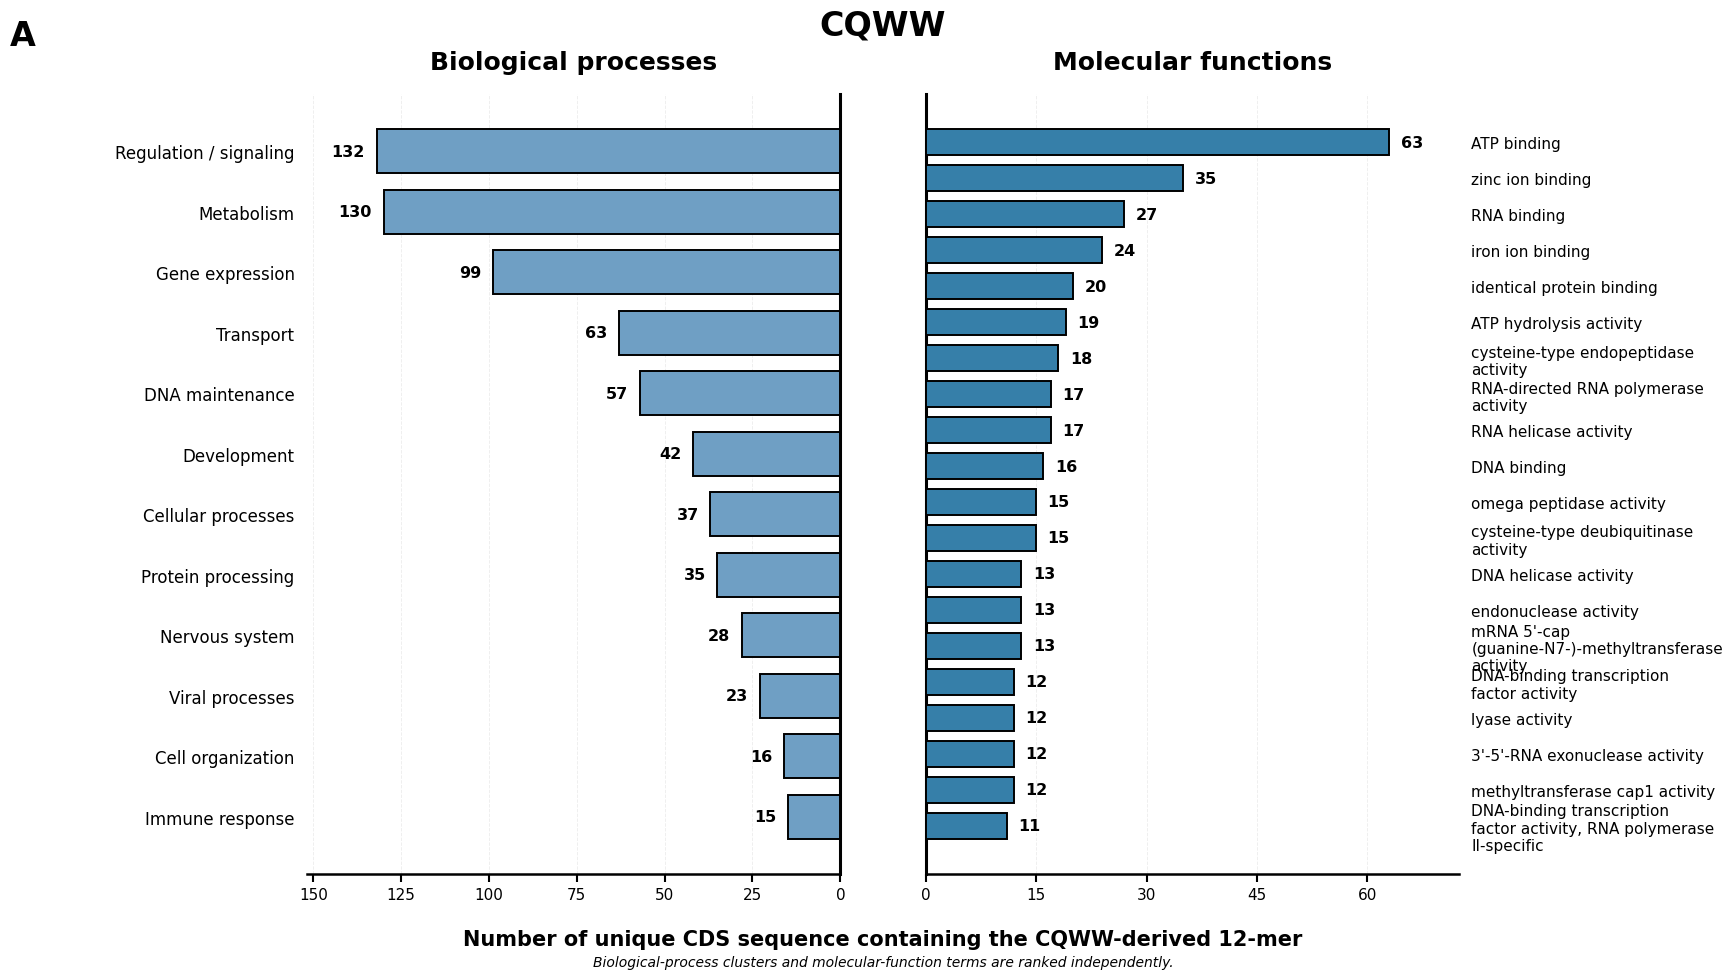


FIGURE SAVED SUCCESSFULLY
TIFF : /content/CQWW_GO_Combined_BP_MF.tiff
PNG  : /content/CQWW_GO_Combined_BP_MF.png
PDF  : /content/CQWW_GO_Combined_BP_MF.pdf


In [ ]:
# ============================================================
# COMBINED CQWW GO FIGURE
# Biological Processes + Molecular Functions
#
# LEFT  : Biological Process clusters
# RIGHT : GO Molecular Functions
#
# Values = number of UNIQUE UniProt IDs present in CQWW_GO.csv
# No denominator / background total is introduced.
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from collections import defaultdict
import textwrap
import os


# ============================================================
# 1. SETTINGS
# ============================================================

FILE_PATH = r"CQWW_GO.csv"

CHUNK_SIZE = 10000

# Molecular Function:
# 15 = show top 15 terms
# None = show ALL molecular-function terms
TOP_N_MF = 20

# Biological Processes:
# There are currently 12 manually defined clusters,
# so all of them are shown.
TOP_N_BP = None


# ------------------------------------------------------------
# FIGURE SETTINGS
# ------------------------------------------------------------

FIG_WIDTH = 18
FIG_HEIGHT = 10

OUTPUT_DPI = 600

OUTPUT_TIFF = "CQWW_GO_Combined_BP_MF.tiff"
OUTPUT_PNG  = "CQWW_GO_Combined_BP_MF.png"
OUTPUT_PDF  = "CQWW_GO_Combined_BP_MF.pdf"


# ------------------------------------------------------------
# FONT SETTINGS
# ------------------------------------------------------------

plt.rcParams["font.family"] = "Arial"
plt.rcParams["axes.linewidth"] = 1.8
plt.rcParams["pdf.fonttype"] = 42
plt.rcParams["ps.fonttype"] = 42


# ------------------------------------------------------------
# COLOURS
# Change here if required
# ------------------------------------------------------------

BP_COLOR = "#6F9FC4"
MF_COLOR = "#367FA9"

EDGE_COLOR = "black"


# ============================================================
# 2. DEFINE BIOLOGICAL PROCESS CLUSTERS
# ============================================================

bp_clusters = {

    "Viral processes": [
        "viral",
        "symbiont",
        "virion"
    ],

    "Gene expression": [
        "transcription",
        "translation",
        "ribosome",
        "mirna",
        "rna",
        "preribosome"
    ],

    "DNA maintenance": [
        "dna",
        "recombination",
        "replication",
        "repair"
    ],

    "Metabolism": [
        "metabolic",
        "biosynthetic",
        "respiration",
        "glycolytic",
        "catabolic",
        "glucose",
        "fatty acid"
    ],

    "Cellular processes": [
        "cell cycle",
        "cell division",
        "proliferation",
        "endocytosis",
        "differentiation"
    ],

    "Transport": [
        "transport",
        "secretion",
        "localization",
        "import",
        "translocation"
    ],

    "Nervous system": [
        "neuron",
        "axon",
        "synapse",
        "brain",
        "memory"
    ],

    "Regulation / signaling": [
        "signal",
        "regulation",
        "response",
        "phosphorylation",
        "chromatin"
    ],

    "Protein processing": [
        "proteolysis",
        "ubiquitin",
        "folding"
    ],

    "Cell organization": [
        "cytoskeleton",
        "organelle",
        "adhesion"
    ],

    "Immune response": [
        "defense",
        "apoptotic",
        "degranulation"
    ],

    "Development": [
        "development",
        "morphogenesis",
        "germination"
    ]
}


# ============================================================
# 3. STORAGE
# ============================================================

# BP cluster -> unique UniProt IDs
cluster_to_proteins = defaultdict(set)

# Molecular Function term -> unique UniProt IDs
mf_to_proteins = defaultdict(set)

# Overall unique proteins appearing in the input file
all_unique_proteins = set()


# ============================================================
# 4. READ CQWW FILE ONCE
# ============================================================

print("=" * 70)
print("CQWW GO ANALYSIS")
print("=" * 70)

print("\nReading file:")
print(FILE_PATH)

required_columns = [
    "uniprot_id",
    "GO_Biological_Process",
    "GO_Molecular_Function"
]


for chunk_number, chunk in enumerate(
    pd.read_csv(
        FILE_PATH,
        chunksize=CHUNK_SIZE,
        usecols=required_columns
    ),
    start=1
):

    print(
        f"\rProcessing chunk {chunk_number:,}...",
        end="",
        flush=True
    )

    # --------------------------------------------------------
    # Remove rows without UniProt ID
    # --------------------------------------------------------

    chunk = chunk.dropna(subset=["uniprot_id"])


    # ========================================================
    # PROCESS EACH ROW
    # ========================================================

    for _, row in chunk.iterrows():

        protein = str(row["uniprot_id"]).strip()

        if not protein:
            continue

        all_unique_proteins.add(protein)


        # ====================================================
        # A. BIOLOGICAL PROCESS
        # ====================================================

        bp_entry = row["GO_Biological_Process"]

        if pd.notna(bp_entry):

            bp_terms = str(bp_entry).split(";")

            for term in bp_terms:

                term_lower = term.lower().strip()

                if not term_lower:
                    continue

                # Match the GO term against every BP cluster
                for cluster, keywords in bp_clusters.items():

                    if any(
                        keyword in term_lower
                        for keyword in keywords
                    ):

                        cluster_to_proteins[cluster].add(
                            protein
                        )


        # ====================================================
        # B. MOLECULAR FUNCTION
        # ====================================================

        mf_entry = row["GO_Molecular_Function"]

        if pd.notna(mf_entry):

            mf_terms = str(mf_entry).split(";")

            for term in mf_terms:

                term = term.strip()

                if term:

                    mf_to_proteins[term].add(
                        protein
                    )


print("\n\nFinished processing.")


# ============================================================
# 5. BIOLOGICAL PROCESS COUNTS
# ============================================================

# Include every predefined BP cluster, even if count = 0
bp_counts = {

    cluster: len(
        cluster_to_proteins.get(cluster, set())
    )

    for cluster in bp_clusters.keys()
}


bp_df = pd.DataFrame(

    bp_counts.items(),

    columns=[
        "Biological Process Cluster",
        "Protein Count"
    ]
)


# Sort from largest to smallest
bp_df = bp_df.sort_values(

    by="Protein Count",
    ascending=False

).reset_index(drop=True)


# Optional BP limit
if TOP_N_BP is not None:

    bp_df = bp_df.head(TOP_N_BP)


# ============================================================
# 6. MOLECULAR FUNCTION COUNTS
# ============================================================

mf_counts = {

    term: len(proteins)

    for term, proteins
    in mf_to_proteins.items()
}


mf_df = pd.DataFrame(

    mf_counts.items(),

    columns=[
        "GO Molecular Function",
        "Protein Count"
    ]
)


# Sort from largest to smallest
mf_df = mf_df.sort_values(

    by="Protein Count",
    ascending=False

).reset_index(drop=True)


# Select top MF terms if requested
if TOP_N_MF is not None:

    mf_df = mf_df.head(TOP_N_MF)


# ============================================================
# 7. PRINT RESULTS
# ============================================================

print("\n" + "=" * 70)
print("SUMMARY")
print("=" * 70)

print(
    f"\nTotal unique UniProt IDs in CQWW_GO.csv: "
    f"{len(all_unique_proteins):,}"
)

print(
    f"Biological Process clusters shown: "
    f"{len(bp_df)}"
)

print(
    f"Molecular Function terms shown: "
    f"{len(mf_df)}"
)


print("\nBIOLOGICAL PROCESS COUNTS")
print("-" * 70)

print(
    bp_df.to_string(
        index=False
    )
)


print("\nMOLECULAR FUNCTION COUNTS")
print("-" * 70)

print(
    mf_df.to_string(
        index=False
    )
)


# ============================================================
# 8. TEXT-WRAPPING FUNCTION
# ============================================================

def wrap_label(label, width=30):
    """
    Wrap long labels onto multiple lines without
    shortening the biological terminology.
    """

    return "\n".join(
        textwrap.wrap(
            str(label),
            width=width,
            break_long_words=False,
            break_on_hyphens=False
        )
    )


# BP names are generally shorter
bp_labels = [

    wrap_label(x, width=25)

    for x in
    bp_df["Biological Process Cluster"]
]


# MF terms can be much longer
mf_labels = [

    wrap_label(x, width=31)

    for x in
    mf_df["GO Molecular Function"]
]


bp_values = bp_df[
    "Protein Count"
].to_numpy()


mf_values = mf_df[
    "Protein Count"
].to_numpy()


# ============================================================
# 9. CREATE COMBINED FIGURE
# ============================================================

fig = plt.figure(

    figsize=(
        FIG_WIDTH,
        FIG_HEIGHT
    ),

    facecolor="white"
)


# ------------------------------------------------------------
# GridSpec:
# equal plotting widths with a small central separation
# ------------------------------------------------------------

gs = fig.add_gridspec(

    nrows=1,
    ncols=2,

    width_ratios=[
        1,
        1
    ],

    wspace=0.16
)


ax_bp = fig.add_subplot(
    gs[0, 0]
)

ax_mf = fig.add_subplot(
    gs[0, 1]
)


ax_bp.set_facecolor("white")
ax_mf.set_facecolor("white")


# ============================================================
# 10. LEFT PANEL:
#     BIOLOGICAL PROCESS
# ============================================================

bp_y = range(
    len(bp_df)
)


bars_bp = ax_bp.barh(

    bp_y,

    bp_values,

    height=0.72,

    color=BP_COLOR,

    edgecolor=EDGE_COLOR,

    linewidth=1.4,

    zorder=3
)


# Highest value at top
ax_bp.invert_yaxis()


# IMPORTANT:
# reverse x-axis so bars extend LEFT from centre
ax_bp.invert_xaxis()


# ------------------------------------------------------------
# BP y-axis labels
# ------------------------------------------------------------

ax_bp.set_yticks(
    list(bp_y)
)

ax_bp.set_yticklabels(

    bp_labels,

    fontsize=12,

    fontweight="normal"
)


# Keep labels on OUTER / LEFT side
ax_bp.yaxis.tick_left()


# ------------------------------------------------------------
# BP VALUE LABELS
# ------------------------------------------------------------

bp_max = max(bp_values) if len(bp_values) else 1

bp_padding = bp_max * 0.025


for bar, value in zip(
    bars_bp,
    bp_values
):

    y_position = (
        bar.get_y()
        +
        bar.get_height() / 2
    )

    # Because axis is reversed, a slightly larger x
    # position places text beyond the free end of the bar
    ax_bp.text(

        value + bp_padding,

        y_position,

        f"{int(value):,}",

        ha="right",

        va="center",

        fontsize=11.5,

        fontweight="bold",

        color="black",

        zorder=5
    )


# ------------------------------------------------------------
# BP title
# ------------------------------------------------------------

ax_bp.set_title(

    "Biological processes",

    fontsize=18,

    fontweight="bold",

    pad=18
)


# ============================================================
# 11. RIGHT PANEL:
#     MOLECULAR FUNCTION
# ============================================================

mf_y = range(
    len(mf_df)
)


bars_mf = ax_mf.barh(

    mf_y,

    mf_values,

    height=0.72,

    color=MF_COLOR,

    edgecolor=EDGE_COLOR,

    linewidth=1.4,

    zorder=3
)


# Highest value at top
ax_mf.invert_yaxis()


# ------------------------------------------------------------
# MF labels
# ------------------------------------------------------------

ax_mf.set_yticks(
    list(mf_y)
)

ax_mf.set_yticklabels(

    mf_labels,

    fontsize=11,

    fontweight="normal"
)


# Put MF labels on the OUTER / RIGHT side
ax_mf.yaxis.tick_right()


# ------------------------------------------------------------
# MF value labels
# ------------------------------------------------------------

mf_max = max(mf_values) if len(mf_values) else 1

mf_padding = mf_max * 0.025


for bar, value in zip(
    bars_mf,
    mf_values
):

    y_position = (
        bar.get_y()
        +
        bar.get_height() / 2
    )

    ax_mf.text(

        value + mf_padding,

        y_position,

        f"{int(value):,}",

        ha="left",

        va="center",

        fontsize=11.5,

        fontweight="bold",

        color="black",

        zorder=5
    )


# ------------------------------------------------------------
# MF title
# ------------------------------------------------------------

ax_mf.set_title(

    "Molecular functions",

    fontsize=18,

    fontweight="bold",

    pad=18
)


# ============================================================
# 12. AXIS LIMITS
# ============================================================

# Add enough empty space for value labels

ax_bp.set_xlim(

    bp_max * 1.15,

    0
)


ax_mf.set_xlim(

    0,

    mf_max * 1.15
)


# ============================================================
# 13. INTEGER X-AXIS TICKS
# ============================================================

ax_bp.xaxis.set_major_locator(

    MaxNLocator(
        integer=True,
        nbins=7
    )
)


ax_mf.xaxis.set_major_locator(

    MaxNLocator(
        integer=True,
        nbins=7
    )
)


# ============================================================
# 14. AXIS STYLING
# ============================================================

for ax in [
    ax_bp,
    ax_mf
]:

    # Bottom x-axis
    ax.spines["bottom"].set_linewidth(
        1.8
    )

    # No top border
    ax.spines["top"].set_visible(
        False
    )

    # X-axis ticks
    ax.tick_params(

        axis="x",

        which="major",

        direction="out",

        length=6,

        width=1.5,

        labelsize=11
    )

    # Remove small tick marks beside category names
    ax.tick_params(

        axis="y",

        length=0,

        pad=9
    )

    # Light guide lines
    ax.xaxis.grid(

        True,

        linestyle="--",

        linewidth=0.65,

        alpha=0.22,

        zorder=0
    )


# ============================================================
# 15. CENTRAL DIVIDER
# ============================================================

# Biological-process axis:
# right spine acts as left-half centre line

ax_bp.spines["right"].set_visible(
    True
)

ax_bp.spines["right"].set_linewidth(
    2.2
)

ax_bp.spines["right"].set_color(
    "black"
)


# Remove outer left border
ax_bp.spines["left"].set_visible(
    False
)


# Molecular-function axis:
# left spine acts as right-half centre line

ax_mf.spines["left"].set_visible(
    True
)

ax_mf.spines["left"].set_linewidth(
    2.2
)

ax_mf.spines["left"].set_color(
    "black"
)


# Remove outer right border
ax_mf.spines["right"].set_visible(
    False
)


# ============================================================
# 16. MAIN FIGURE TITLE
# ============================================================

fig.suptitle(

    "CQWW",

    fontsize=24,

    fontweight="bold",

    y=0.975
)


# ============================================================
# 17. SINGLE COMMON X-AXIS DESCRIPTION
# ============================================================

fig.text(

    0.5,

    0.045,

    "Number of unique CDS sequence containing the CQWW-derived 12-mer",

    ha="center",

    va="center",

    fontsize=15,

    fontweight="bold"
)


# ============================================================
# 18. OPTIONAL PANEL LABEL
# ============================================================

fig.text(

    0.015,

    0.965,

    "A",

    fontsize=24,

    fontweight="bold",

    ha="left",

    va="top"
)


# ============================================================
# 19. SMALL INTERPRETATION NOTE
# ============================================================

fig.text(

    0.5,

    0.015,

    "Biological-process clusters and molecular-function terms are ranked independently.",

    ha="center",

    va="bottom",

    fontsize=10,

    fontstyle="italic"
)


# ============================================================
# 20. MANUAL LAYOUT
#
# Extra room is intentionally left on:
# LEFT  -> biological-process labels
# RIGHT -> long molecular-function labels
# ============================================================

plt.subplots_adjust(

    left=0.18,

    right=0.82,

    top=0.89,

    bottom=0.11
)


# ============================================================
# 21. SAVE HIGH-RESOLUTION OUTPUTS
# ============================================================

plt.savefig(

    OUTPUT_TIFF,

    dpi=OUTPUT_DPI,

    bbox_inches="tight",

    facecolor="white",

    pil_kwargs={
        "compression": "tiff_lzw"
    }
)


plt.savefig(

    OUTPUT_PNG,

    dpi=OUTPUT_DPI,

    bbox_inches="tight",

    facecolor="white"
)


plt.savefig(

    OUTPUT_PDF,

    bbox_inches="tight",

    facecolor="white"
)


# ============================================================
# 22. DISPLAY
# ============================================================

plt.show()


# ============================================================
# 23. OUTPUT CONFIRMATION
# ============================================================

print("\n" + "=" * 70)
print("FIGURE SAVED SUCCESSFULLY")
print("=" * 70)

print(
    f"TIFF : {os.path.abspath(OUTPUT_TIFF)}"
)

print(
    f"PNG  : {os.path.abspath(OUTPUT_PNG)}"
)

print(
    f"PDF  : {os.path.abspath(OUTPUT_PDF)}"
)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
SEARCHING GOOGLE DRIVE FOR:
pep_GO.csv

File found successfully:
/content/drive/MyDrive/pep_GO.csv

Required columns confirmed.

PENTAPEPTIDE GO ANALYSIS

Reading file in chunks...
Processing chunk 143...

Finished processing.

SUMMARY

Total unique UniProt IDs in pep_GO.csv: 380,950
Biological-process clusters shown: 12
Molecular-function terms shown: 20

BIOLOGICAL PROCESS COUNTS
--------------------------------------------------------------------------------
Biological Process Cluster  Protein Count
                Metabolism         120276
    Regulation / signaling          79041
           Gene expression          77812
                 Transport          36518
           DNA maintenance          33610
        Cellular processes          24451
        Protein processing          18883
               Development          17497
           Immune response 

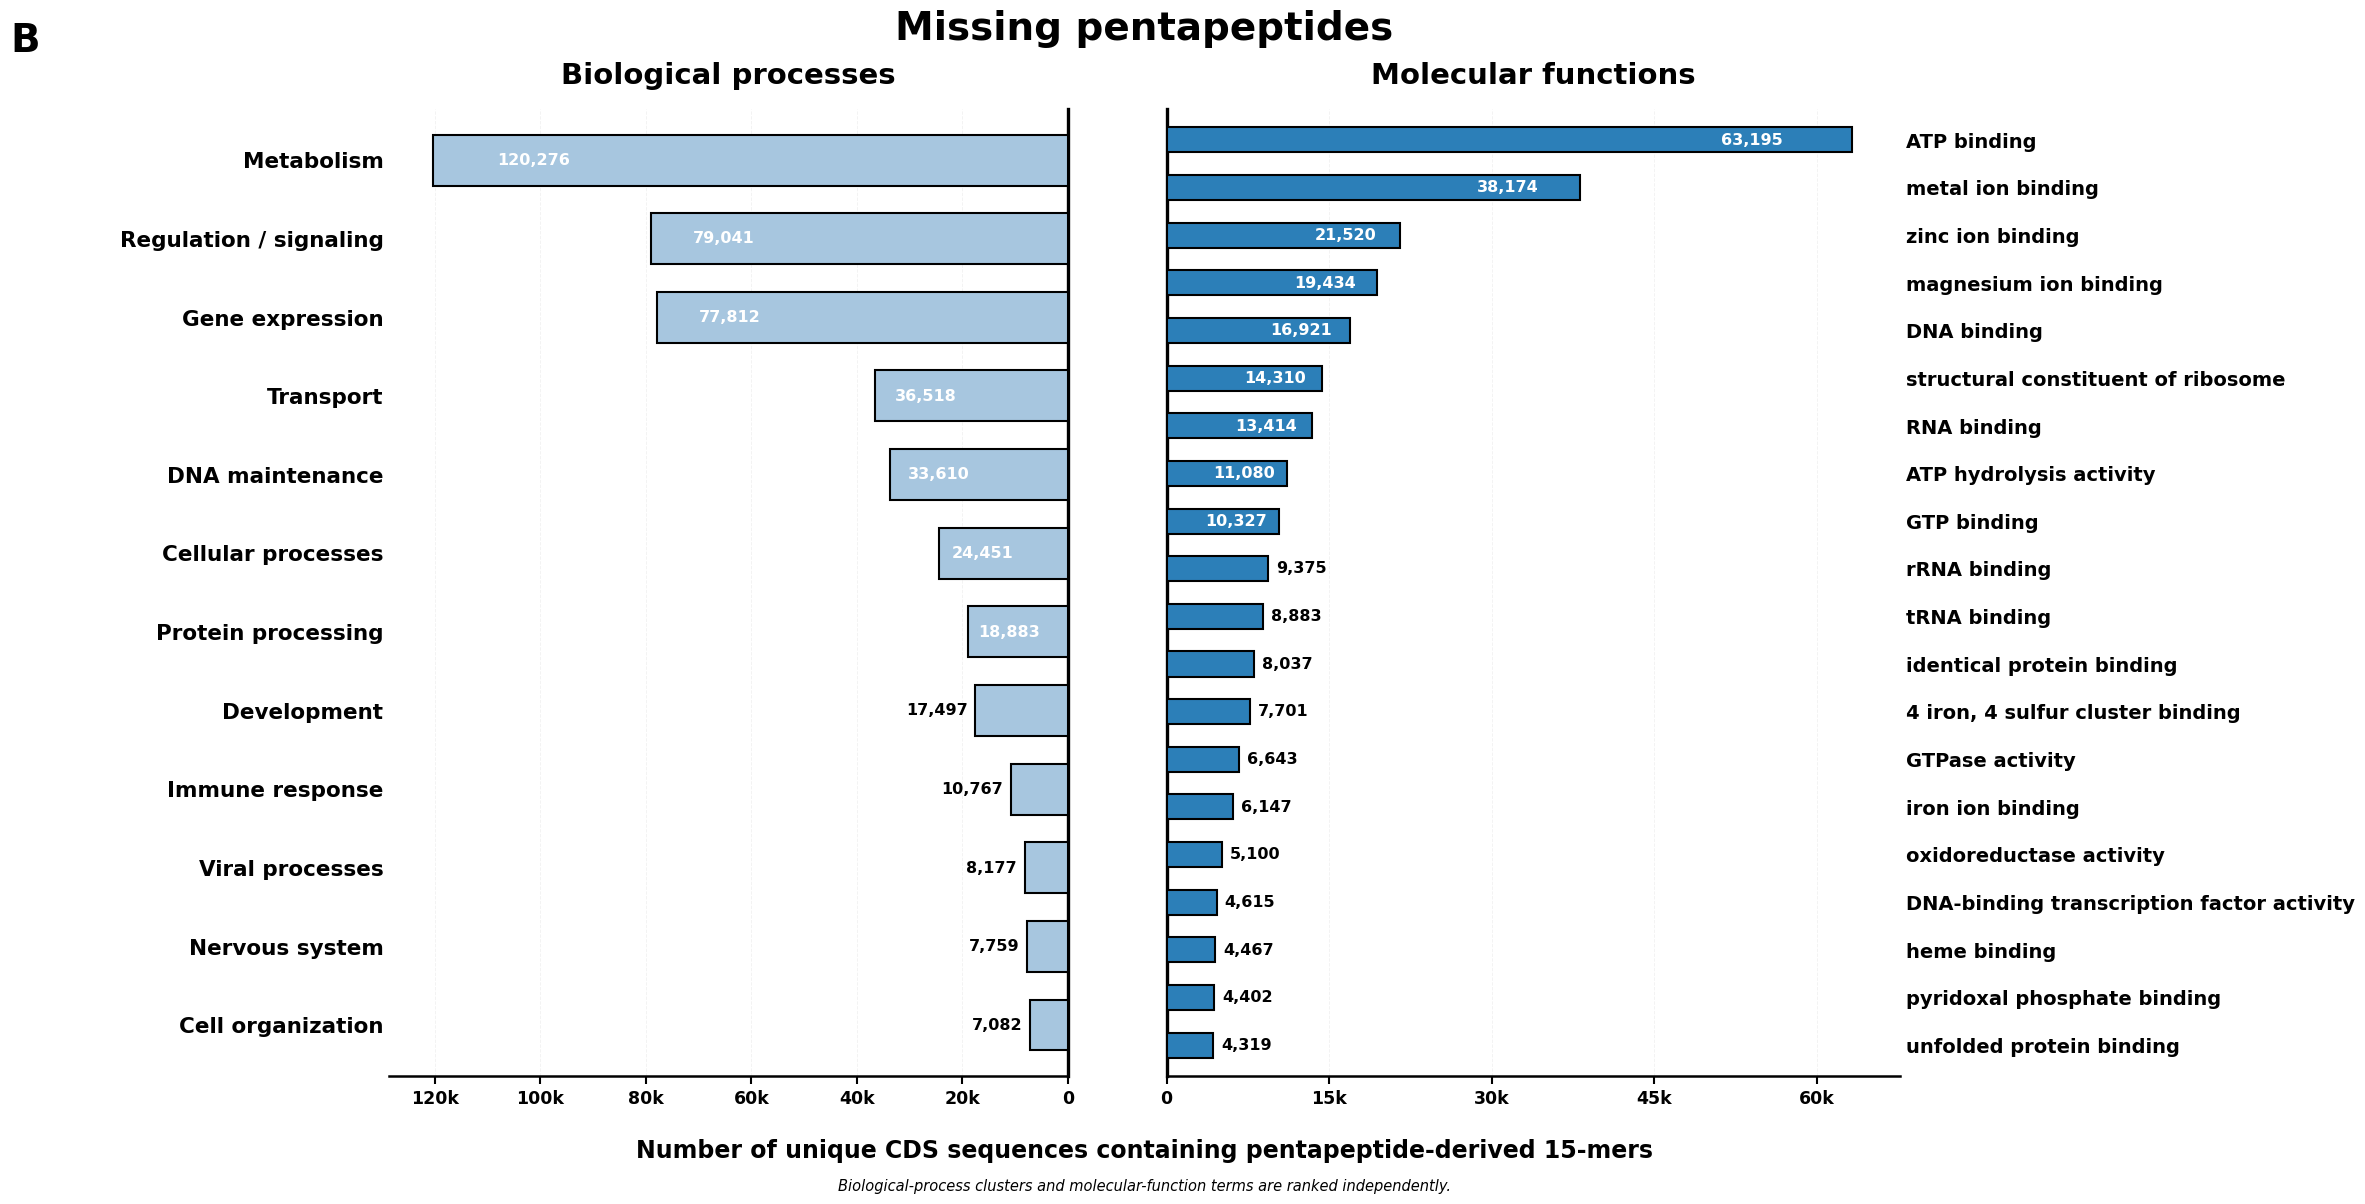


FIGURE SAVED SUCCESSFULLY

TIFF: /content/Pentapeptide_GO_Combined_BP_MF_Top20_Final.tiff
PNG : /content/Pentapeptide_GO_Combined_BP_MF_Top20_Final.png
PDF : /content/Pentapeptide_GO_Combined_BP_MF_Top20_Final.pdf

Numerical result files:
/content/Pentapeptide_Biological_Process_Counts.csv
/content/Pentapeptide_Molecular_Function_Top20_Counts.csv


In [ ]:
# ============================================================
# COMBINED PENTAPEPTIDE GO FIGURE
# Biological Processes + Molecular Functions
#
# LEFT  : Biological Process clusters
# RIGHT : GO Molecular Functions
#
# Input : pep_GO.csv stored in Google Drive
#
# Values = number of UNIQUE UniProt IDs associated with
#          pentapeptide-derived 15-mer occurrences
#
# No denominator/background total is introduced.
# ============================================================


# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from collections import defaultdict
import textwrap
import os


# ============================================================
# 2. MOUNT GOOGLE DRIVE
# ============================================================

from google.colab import drive

drive.mount('/content/drive')


# ============================================================
# 3. AUTOMATICALLY FIND pep_GO.csv IN GOOGLE DRIVE
# ============================================================

TARGET_FILE = "pep_GO.csv"

SEARCH_ROOT = "/content/drive/MyDrive"

FILE_PATH = None


print("=" * 75)
print("SEARCHING GOOGLE DRIVE FOR:")
print(TARGET_FILE)
print("=" * 75)


for root, dirs, files in os.walk(SEARCH_ROOT):

    if TARGET_FILE in files:

        FILE_PATH = os.path.join(
            root,
            TARGET_FILE
        )

        break


if FILE_PATH is None:

    raise FileNotFoundError(
        f"\n{TARGET_FILE} was not found anywhere inside:\n"
        f"{SEARCH_ROOT}\n\n"
        "Please check the filename."
    )


print("\nFile found successfully:")
print(FILE_PATH)


# ============================================================
# 4. ANALYSIS SETTINGS
# ============================================================

CHUNK_SIZE = 10000


# ------------------------------------------------------------
# MOLECULAR FUNCTION DISPLAY
#
# 15   -> show top 15 Molecular Functions
# None -> show ALL Molecular Functions
# ------------------------------------------------------------

TOP_N_MF = 15


# ------------------------------------------------------------
# BIOLOGICAL PROCESS DISPLAY
#
# None = show all predefined BP clusters
# ------------------------------------------------------------

TOP_N_BP = None


# ============================================================
# 5. FIGURE SETTINGS
# ============================================================

FIG_WIDTH = 18
FIG_HEIGHT = 10

OUTPUT_DPI = 600


OUTPUT_TIFF = (
    "Pentapeptide_GO_Combined_BP_MF.tiff"
)

OUTPUT_PNG = (
    "Pentapeptide_GO_Combined_BP_MF.png"
)

OUTPUT_PDF = (
    "Pentapeptide_GO_Combined_BP_MF.pdf"
)


# ============================================================
# 6. FONT SETTINGS
# ============================================================

plt.rcParams["font.family"] = "Arial"

plt.rcParams["axes.linewidth"] = 1.8

# Keep fonts editable in vector PDF
plt.rcParams["pdf.fonttype"] = 42
plt.rcParams["ps.fonttype"] = 42


# ============================================================
# 7. COLOUR SETTINGS
#
# These may be changed later if you want CQWW and
# pentapeptides to have different manuscript colours.
# ============================================================

BP_COLOR = "#A7C6DF"

MF_COLOR = "#2C7FB8"

EDGE_COLOR = "black"


# ============================================================
# 8. DEFINE BIOLOGICAL PROCESS CLUSTERS
#
# SAME CLUSTER DEFINITIONS AS CQWW
#
# This is important because it makes the CQWW and
# pentapeptide figures directly comparable.
# ============================================================

bp_clusters = {

    "Viral processes": [

        "viral",
        "symbiont",
        "virion"
    ],


    "Gene expression": [

        "transcription",
        "translation",
        "ribosome",
        "mirna",
        "rna",
        "preribosome"
    ],


    "DNA maintenance": [

        "dna",
        "recombination",
        "replication",
        "repair"
    ],


    "Metabolism": [

        "metabolic",
        "biosynthetic",
        "respiration",
        "glycolytic",
        "catabolic",
        "glucose",
        "fatty acid"
    ],


    "Cellular processes": [

        "cell cycle",
        "cell division",
        "proliferation",
        "endocytosis",
        "differentiation"
    ],


    "Transport": [

        "transport",
        "secretion",
        "localization",
        "import",
        "translocation"
    ],


    "Nervous system": [

        "neuron",
        "axon",
        "synapse",
        "brain",
        "memory"
    ],


    "Regulation / signaling": [

        "signal",
        "regulation",
        "response",
        "phosphorylation",
        "chromatin"
    ],


    "Protein processing": [

        "proteolysis",
        "ubiquitin",
        "folding"
    ],


    "Cell organization": [

        "cytoskeleton",
        "organelle",
        "adhesion"
    ],


    "Immune response": [

        "defense",
        "apoptotic",
        "degranulation"
    ],


    "Development": [

        "development",
        "morphogenesis",
        "germination"
    ]
}


# ============================================================
# 9. STORAGE
# ============================================================

# Biological Process cluster
# -> unique UniProt IDs
cluster_to_proteins = defaultdict(set)


# Molecular Function GO term
# -> unique UniProt IDs
mf_to_proteins = defaultdict(set)


# Store all unique proteins present in pep_GO.csv
all_unique_proteins = set()


# ============================================================
# 10. REQUIRED COLUMNS
# ============================================================

required_columns = [

    "uniprot_id",
    "GO_Biological_Process",
    "GO_Molecular_Function"
]


# ============================================================
# 11. CHECK THAT REQUIRED COLUMNS EXIST
# ============================================================

header = pd.read_csv(
    FILE_PATH,
    nrows=0
)


missing_columns = [

    col
    for col in required_columns
    if col not in header.columns
]


if missing_columns:

    raise ValueError(

        "\nThe following required columns are missing "
        "from pep_GO.csv:\n\n"
        + "\n".join(missing_columns)
        +
        "\n\nAvailable columns are:\n"
        +
        "\n".join(header.columns.astype(str))
    )


print("\nRequired columns confirmed.")


# ============================================================
# 12. READ pep_GO.csv IN CHUNKS
# ============================================================

print("\n" + "=" * 75)

print("PENTAPEPTIDE GO ANALYSIS")

print("=" * 75)


print("\nReading file in chunks...")


for chunk_number, chunk in enumerate(

    pd.read_csv(

        FILE_PATH,

        chunksize=CHUNK_SIZE,

        usecols=required_columns

    ),

    start=1

):


    print(

        f"\rProcessing chunk "
        f"{chunk_number:,}...",

        end="",

        flush=True
    )


    # --------------------------------------------------------
    # Remove rows without UniProt ID
    # --------------------------------------------------------

    chunk = chunk.dropna(

        subset=[
            "uniprot_id"
        ]
    )


    # ========================================================
    # PROCESS EACH ROW
    # ========================================================

    for _, row in chunk.iterrows():


        # ----------------------------------------------------
        # UniProt ID
        # ----------------------------------------------------

        protein = str(
            row["uniprot_id"]
        ).strip()


        if not protein:

            continue


        all_unique_proteins.add(
            protein
        )


        # ====================================================
        # A. BIOLOGICAL PROCESS
        # ====================================================

        bp_entry = row[
            "GO_Biological_Process"
        ]


        if pd.notna(bp_entry):


            # Multiple GO terms are separated by ;
            bp_terms = str(
                bp_entry
            ).split(";")


            for term in bp_terms:


                term_lower = (
                    term
                    .lower()
                    .strip()
                )


                if not term_lower:

                    continue


                # --------------------------------------------
                # Compare GO term against every broad
                # Biological Process cluster
                # --------------------------------------------

                for cluster, keywords in bp_clusters.items():


                    if any(

                        keyword in term_lower

                        for keyword in keywords

                    ):


                        cluster_to_proteins[
                            cluster
                        ].add(
                            protein
                        )


        # ====================================================
        # B. MOLECULAR FUNCTION
        # ====================================================

        mf_entry = row[
            "GO_Molecular_Function"
        ]


        if pd.notna(mf_entry):


            mf_terms = str(
                mf_entry
            ).split(";")


            for term in mf_terms:


                term = term.strip()


                if term:


                    mf_to_proteins[
                        term
                    ].add(
                        protein
                    )


print("\n\nFinished processing.")


# ============================================================
# 13. BIOLOGICAL PROCESS COUNTS
# ============================================================

# Include every predefined cluster.
# If one cluster has no proteins, its count becomes zero.

bp_counts = {


    cluster:

    len(

        cluster_to_proteins.get(

            cluster,

            set()

        )

    )


    for cluster in bp_clusters.keys()

}


# ============================================================
# 14. BIOLOGICAL PROCESS DATAFRAME
# ============================================================

bp_df = pd.DataFrame(

    bp_counts.items(),

    columns=[

        "Biological Process Cluster",

        "Protein Count"

    ]

)


# Sort highest -> lowest

bp_df = bp_df.sort_values(

    by="Protein Count",

    ascending=False

).reset_index(
    drop=True
)


# Optional BP selection

if TOP_N_BP is not None:

    bp_df = bp_df.head(
        TOP_N_BP
    )


# ============================================================
# 15. MOLECULAR FUNCTION COUNTS
# ============================================================

mf_counts = {


    term:

    len(proteins)


    for term, proteins

    in mf_to_proteins.items()

}


# ============================================================
# 16. MOLECULAR FUNCTION DATAFRAME
# ============================================================

mf_df = pd.DataFrame(

    mf_counts.items(),

    columns=[

        "GO Molecular Function",

        "Protein Count"

    ]

)


# Sort highest -> lowest

mf_df = mf_df.sort_values(

    by="Protein Count",

    ascending=False

).reset_index(
    drop=True
)


# Select top molecular functions

if TOP_N_MF is not None:

    mf_df = mf_df.head(
        TOP_N_MF
    )


# ============================================================
# 17. PRINT ANALYSIS SUMMARY
# ============================================================

print("\n" + "=" * 75)

print("SUMMARY")

print("=" * 75)


print(

    "\nTotal unique UniProt IDs "
    "in pep_GO.csv: "
    f"{len(all_unique_proteins):,}"

)


print(

    "Biological Process clusters "
    f"shown: {len(bp_df):,}"

)


print(

    "Molecular Function terms "
    f"shown: {len(mf_df):,}"

)


# ============================================================
# 18. PRINT BIOLOGICAL PROCESS RESULTS
# ============================================================

print("\n" + "=" * 75)

print("BIOLOGICAL PROCESS COUNTS")

print("=" * 75)


print(

    bp_df.to_string(

        index=False

    )

)


# ============================================================
# 19. PRINT MOLECULAR FUNCTION RESULTS
# ============================================================

print("\n" + "=" * 75)

print("MOLECULAR FUNCTION COUNTS")

print("=" * 75)


print(

    mf_df.to_string(

        index=False

    )

)


# ============================================================
# 20. OPTIONAL:
# SAVE THE NUMERICAL RESULTS AS CSV
# ============================================================

bp_df.to_csv(

    "Pentapeptide_Biological_Process_Counts.csv",

    index=False

)


mf_df.to_csv(

    "Pentapeptide_Molecular_Function_Counts.csv",

    index=False

)


print(
    "\nNumerical result tables saved."
)


# ============================================================
# 21. TEXT WRAPPING FUNCTION
# ============================================================

def wrap_label(
    label,
    width=30
):

    """
    Wrap long biological labels over multiple lines
    without shortening their terminology.
    """

    return "\n".join(

        textwrap.wrap(

            str(label),

            width=width,

            break_long_words=False,

            break_on_hyphens=False

        )

    )


# ============================================================
# 22. PREPARE LABELS
# ============================================================

bp_labels = [

    wrap_label(
        x,
        width=25
    )

    for x in

    bp_df[
        "Biological Process Cluster"
    ]

]


mf_labels = [

    wrap_label(
        x,
        width=31
    )

    for x in

    mf_df[
        "GO Molecular Function"
    ]

]


# ============================================================
# 23. PREPARE VALUES
# ============================================================

bp_values = (

    bp_df[
        "Protein Count"
    ]
    .to_numpy()

)


mf_values = (

    mf_df[
        "Protein Count"
    ]
    .to_numpy()

)


# ============================================================
# 24. CREATE FIGURE
# ============================================================

fig = plt.figure(

    figsize=(

        FIG_WIDTH,

        FIG_HEIGHT

    ),

    facecolor="white"

)


# ============================================================
# 25. CREATE TWO-SIDED GRID
# ============================================================

gs = fig.add_gridspec(

    nrows=1,

    ncols=2,

    width_ratios=[

        1,

        1

    ],

    wspace=0.16

)


# Left plot
ax_bp = fig.add_subplot(

    gs[
        0,
        0
    ]

)


# Right plot
ax_mf = fig.add_subplot(

    gs[
        0,
        1
    ]

)


ax_bp.set_facecolor(
    "white"
)

ax_mf.set_facecolor(
    "white"
)


# ============================================================
# 26. BIOLOGICAL PROCESS — LEFT SIDE
# ============================================================

bp_y = range(
    len(bp_df)
)


bars_bp = ax_bp.barh(

    bp_y,

    bp_values,

    height=0.72,

    color=BP_COLOR,

    edgecolor=EDGE_COLOR,

    linewidth=1.4,

    zorder=3

)


# Highest count at top
ax_bp.invert_yaxis()


# Reverse X axis:
# bars extend toward the LEFT
ax_bp.invert_xaxis()


# ============================================================
# 27. BP CATEGORY LABELS
# ============================================================

ax_bp.set_yticks(

    list(
        bp_y
    )

)


ax_bp.set_yticklabels(

    bp_labels,

    fontsize=12,

    fontweight="normal"

)


# Labels outside left side
ax_bp.yaxis.tick_left()


# ============================================================
# 28. BP VALUE LABELS
# ============================================================

bp_max = (

    max(bp_values)

    if len(bp_values)

    else 1

)


bp_padding = (

    bp_max
    *
    0.025

)


for bar, value in zip(

    bars_bp,

    bp_values

):


    y_position = (

        bar.get_y()

        +

        bar.get_height() / 2

    )


    ax_bp.text(

        value + bp_padding,

        y_position,

        f"{int(value):,}",

        ha="right",

        va="center",

        fontsize=11.5,

        fontweight="bold",

        color="black",

        zorder=5

    )


# ============================================================
# 29. BP TITLE
# ============================================================

ax_bp.set_title(

    "Biological processes",

    fontsize=18,

    fontweight="bold",

    pad=18

)


# ============================================================
# 30. MOLECULAR FUNCTION — RIGHT SIDE
# ============================================================

mf_y = range(
    len(mf_df)
)


bars_mf = ax_mf.barh(

    mf_y,

    mf_values,

    height=0.72,

    color=MF_COLOR,

    edgecolor=EDGE_COLOR,

    linewidth=1.4,

    zorder=3

)


# Highest count at top
ax_mf.invert_yaxis()


# ============================================================
# 31. MF CATEGORY LABELS
# ============================================================

ax_mf.set_yticks(

    list(
        mf_y
    )

)


ax_mf.set_yticklabels(

    mf_labels,

    fontsize=11,

    fontweight="normal"

)


# MF terms appear outside RIGHT side
ax_mf.yaxis.tick_right()


# ============================================================
# 32. MF VALUE LABELS
# ============================================================

mf_max = (

    max(mf_values)

    if len(mf_values)

    else 1

)


mf_padding = (

    mf_max
    *
    0.025

)


for bar, value in zip(

    bars_mf,

    mf_values

):


    y_position = (

        bar.get_y()

        +

        bar.get_height() / 2

    )


    ax_mf.text(

        value + mf_padding,

        y_position,

        f"{int(value):,}",

        ha="left",

        va="center",

        fontsize=11.5,

        fontweight="bold",

        color="black",

        zorder=5

    )


# ============================================================
# 33. MF TITLE
# ============================================================

ax_mf.set_title(

    "Molecular functions",

    fontsize=18,

    fontweight="bold",

    pad=18

)


# ============================================================
# 34. AXIS LIMITS
#
# Each side is independently scaled.
# This is important because BP and MF counts can have
# substantially different ranges.
# ============================================================

ax_bp.set_xlim(

    bp_max * 1.15,

    0

)


ax_mf.set_xlim(

    0,

    mf_max * 1.15

)


# ============================================================
# 35. INTEGER X-AXIS TICKS
# ============================================================

ax_bp.xaxis.set_major_locator(

    MaxNLocator(

        integer=True,

        nbins=7

    )

)


ax_mf.xaxis.set_major_locator(

    MaxNLocator(

        integer=True,

        nbins=7

    )

)


# ============================================================
# 36. AXIS STYLING
# ============================================================

for ax in [

    ax_bp,

    ax_mf

]:

    # --------------------------------------------------------
    # Bottom axis
    # --------------------------------------------------------

    ax.spines[
        "bottom"
    ].set_linewidth(
        1.8
    )


    # --------------------------------------------------------
    # Remove top border
    # --------------------------------------------------------

    ax.spines[
        "top"
    ].set_visible(
        False
    )


    # --------------------------------------------------------
    # X ticks
    # --------------------------------------------------------

    ax.tick_params(

        axis="x",

        which="major",

        direction="out",

        length=6,

        width=1.5,

        labelsize=11

    )


    # --------------------------------------------------------
    # Remove category tick lines
    # --------------------------------------------------------

    ax.tick_params(

        axis="y",

        length=0,

        pad=9

    )


    # --------------------------------------------------------
    # Very subtle guide grid
    # --------------------------------------------------------

    ax.xaxis.grid(

        True,

        linestyle="--",

        linewidth=0.65,

        alpha=0.22,

        zorder=0

    )


# ============================================================
# 37. CENTRAL DIVIDER
# ============================================================

# ------------------------------------------------------------
# Left plot central border
# ------------------------------------------------------------

ax_bp.spines[
    "right"
].set_visible(
    True
)


ax_bp.spines[
    "right"
].set_linewidth(
    2.2
)


ax_bp.spines[
    "right"
].set_color(
    "black"
)


# Remove outer-left border
ax_bp.spines[
    "left"
].set_visible(
    False
)


# ------------------------------------------------------------
# Right plot central border
# ------------------------------------------------------------

ax_mf.spines[
    "left"
].set_visible(
    True
)


ax_mf.spines[
    "left"
].set_linewidth(
    2.2
)


ax_mf.spines[
    "left"
].set_color(
    "black"
)


# Remove outer-right border
ax_mf.spines[
    "right"
].set_visible(
    False
)


# ============================================================
# 38. MAIN FIGURE TITLE
# ============================================================

fig.suptitle(

    "Missing pentapeptides",

    fontsize=24,

    fontweight="bold",

    y=0.975

)


# ============================================================
# 39. COMMON X-AXIS TITLE
# ============================================================

fig.text(

    0.5,

    0.045,

    (
        "Number of unique sequence IDs containing "
        "pentapeptide-derived 15-mers"
    ),

    ha="center",

    va="center",

    fontsize=15,

    fontweight="bold"

)


# ============================================================
# 40. OPTIONAL PANEL LABEL
# ============================================================

fig.text(

    0.015,

    0.965,

    "B",

    fontsize=24,

    fontweight="bold",

    ha="left",

    va="top"

)


# ============================================================
# 41. SMALL FIGURE NOTE
# ============================================================

fig.text(

    0.5,

    0.015,

    (
        "Biological-process clusters and "
        "molecular-function terms are ranked independently."
    ),

    ha="center",

    va="bottom",

    fontsize=10,

    fontstyle="italic"

)


# ============================================================
# 42. FINAL LAYOUT
#
# Extra room:
# LEFT  -> BP labels
# RIGHT -> long Molecular Function terms
# ============================================================

plt.subplots_adjust(

    left=0.18,

    right=0.82,

    top=0.89,

    bottom=0.11

)


# ============================================================
# 43. SAVE TIFF
# ============================================================

plt.savefig(

    OUTPUT_TIFF,

    dpi=OUTPUT_DPI,

    bbox_inches="tight",

    facecolor="white",

    pil_kwargs={

        "compression":
        "tiff_lzw"

    }

)


# ============================================================
# 44. SAVE PNG
# ============================================================

plt.savefig(

    OUTPUT_PNG,

    dpi=OUTPUT_DPI,

    bbox_inches="tight",

    facecolor="white"

)


# ============================================================
# 45. SAVE VECTOR PDF
# ============================================================

plt.savefig(

    OUTPUT_PDF,

    bbox_inches="tight",

    facecolor="white"

)


# ============================================================
# 46. SHOW FIGURE
# ============================================================

plt.show()


# ============================================================
# 47. OUTPUT CONFIRMATION
# ============================================================

print("\n" + "=" * 75)

print("FIGURE SAVED SUCCESSFULLY")

print("=" * 75)


print(

    "\nTIFF:",

    os.path.abspath(
        OUTPUT_TIFF
    )

)


print(

    "PNG :",

    os.path.abspath(
        OUTPUT_PNG
    )

)


print(

    "PDF :",

    os.path.abspath(
        OUTPUT_PDF
    )

)


print("\nAdditional numerical tables:")

print(
    os.path.abspath(
        "Pentapeptide_Biological_Process_Counts.csv"
    )
)

print(
    os.path.abspath(
        "Pentapeptide_Molecular_Function_Counts.csv"
    )
)